REGRESSION

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

1-Loading and Preprocessing

In [3]:
housing = fetch_california_housing()
df = pd.DataFrame(
    housing.data,
    columns = housing.feature_names
)
df["MedHouseValue"]=housing.target
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseValue
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
print("Dataset Shape: ", df.shape)
df.info()
df.describe()

Dataset Shape:  (20640, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MedInc         20640 non-null  float64
 1   HouseAge       20640 non-null  float64
 2   AveRooms       20640 non-null  float64
 3   AveBedrms      20640 non-null  float64
 4   Population     20640 non-null  float64
 5   AveOccup       20640 non-null  float64
 6   Latitude       20640 non-null  float64
 7   Longitude      20640 non-null  float64
 8   MedHouseValue  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseValue
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [5]:
print(df.isnull().sum())

x = df.drop("MedHouseValue", axis = 1)
y = df["MedHouseValue"]
imputer = SimpleImputer(strategy="median")
x = pd.DataFrame(
    imputer.fit_transform(x),
    columns = x.columns
)
print("Missing values handled successfully")

MedInc           0
HouseAge         0
AveRooms         0
AveBedrms        0
Population       0
AveOccup         0
Latitude         0
Longitude        0
MedHouseValue    0
dtype: int64
Missing values handled successfully


In [6]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)
print("Training data: ",x_train.shape)
print("Testing data: ",x_test.shape)

Training data:  (16512, 8)
Testing data:  (4128, 8)


We use StandardScaler to standardize the features.Scaling is particularly important for Linear Regression and SVR.We will include scaling inside each model's pipeline to avoid data leakage.

2-Regression Algorithm Implementation

A.Linear Regression

In [8]:
lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

lr_model.fit(x_train, y_train)

lr_pred = lr_model.predict(x_test)

print("Linear Regression Completed")

Linear Regression Completed


Linear Regression is a supervised machine learning algorithm.It establishes a linear relationship between independent variables and the target variable.It is suitable for predicting house prices based on different housing features.

B.Decision Tree Regressor

In [10]:
dt_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', DecisionTreeRegressor(random_state=42))
])

dt_model.fit(x_train, y_train)

dt_pred = dt_model.predict(x_test)

print("Decision Tree Regressor Completed")

Decision Tree Regressor Completed


Decision Tree Regressor works by dividing data into smaller groups based on feature values.It can capture nonlinear relationships between housing eatures and house prices.

C.Random Forest Regressor

In [ ]:
rf_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

rf_model.fit(x_train, y_train)

rf_pred = rf_model.predict(x_test)

print("Random Forest Regressor Completed")

Random Forest is an ensemble learning algorithm.It creates multiple decision trees and combines their predictions to improve accuracy.It is suitable for complex datasets and can reduce overfitting compared with a single decision tree.

D.Gradient Boosting Regressor

In [12]:
gb_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', GradientBoostingRegressor(random_state=42))
])

gb_model.fit(x_train, y_train)

gb_pred = gb_model.predict(x_test)

print("Gradient Boosting Regressor Completed")

Gradient Boosting Regressor Completed


Gradient Boosting builds multiple decision trees sequentially.Each new tree attempts to correct the errors made by previous trees.It is useful for improving prediction accuracy.

E.Support Vector Regressor(SVR)

In [13]:
svr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVR(kernel='rbf'))
])

svr_model.fit(x_train, y_train)

svr_pred = svr_model.predict(x_test)

print("Support Vector Regressor Completed")

Support Vector Regressor Completed


Support Vector Regressor is based on Support Vector Machine principles.It tries to find a function that predicts values within an acceptable error margin.The RBF kernel helps capture nonlinear relationships.

3-Model Evaluation and Comparison

In [15]:
models = {
    'Linear Regression': lr_pred,
    'Decision Tree': dt_pred,
    'Random Forest': rf_pred,
    'Gradient Boosting': gb_pred,
    'SVR': svr_pred
}
results = []

for name, predictions in models.items():
    mse = mean_squared_error(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    results.append({
        'Model': name,
        'MSE': mse,
        'MAE': mae,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)
print(results_df)

               Model       MSE       MAE  R2 Score
0  Linear Regression  0.555892  0.533200  0.575788
1      Decision Tree  0.492988  0.453172  0.623791
2      Random Forest  0.255915  0.327766  0.804706
3  Gradient Boosting  0.293999  0.371650  0.775643
4                SVR  0.357004  0.398599  0.727563


Best and Worst model identification

In [16]:
best_model = results_df.loc[
    results_df['R2 Score'].idxmax()
]

worst_model = results_df.loc[
    results_df['R2 Score'].idxmin()
]

print("Best Performing Model:")
print(best_model)

print("\nWorst Performing Model:")
print(worst_model)

Best Performing Model:
Model       Random Forest
MSE              0.255915
MAE              0.327766
R2 Score         0.804706
Name: 2, dtype: object

Worst Performing Model:
Model       Linear Regression
MSE                  0.555892
MAE                    0.5332
R2 Score             0.575788
Name: 0, dtype: object


* The model with the highest R² score is considered the best-performing model.
* The model with the lowest R² score is considered the worst-performing model.
  
We also consider MSE and MAE when comparing the models.

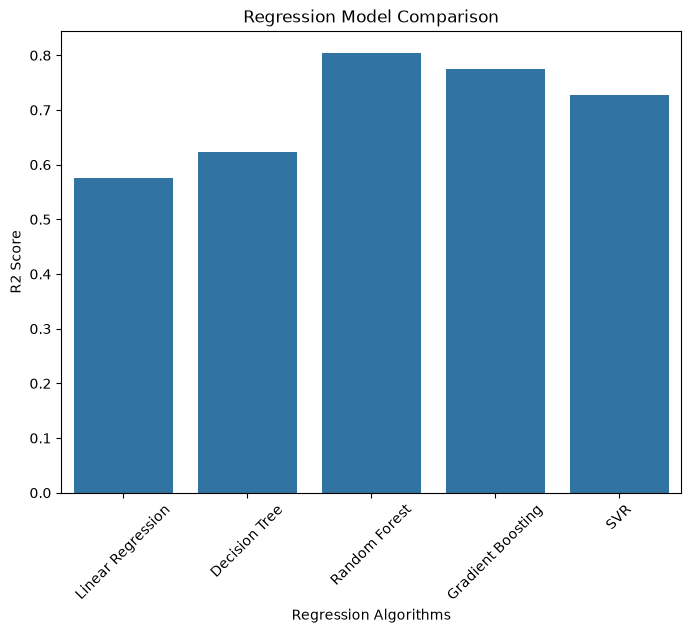

In [20]:
plt.figure(figsize=(8, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)
plt.title('Regression Model Comparison')
plt.xlabel('Regression Algorithms')
plt.ylabel('R2 Score')
plt.xticks(rotation=45)
plt.show()

This bar chart visually compares the R² scores of all five regression algorithms.
The model with the highest bar has the best R² score.